# CS308 Лаборатори 6, 7 — Hyperparameter tuning, KFold, ROC/AUC

**Оюутан:** Б. Өсөхбаяр (B231910012)

Энэ notebook-ийн **1–79 дүгээр нүд нь багшийн эх материал** (5–6-р лабтай
ихэвчлэн давхцана). Миний ажил нь багшийн хоосон үлдээсэн даалгаврын нүднүүд:

| Нүд | Даалгавар |
|---|---|
| 2-р хэсэг | CuPy — GPU хурдасгалт |
| 4-р хэсэг | **Hyperparameter tuning** |
| | Эцсийн загвар + F1 / Precision / Recall / **AUC** |
| | **6-fold cross validation** |
| | **Confusion matrix** |

> **Colab:** `Runtime` → `Change runtime type` → **T4 GPU**.
> Багшийн 76-р нүд 50 epoch сургадаг (~8 мин T4 дээр); миний хэсэг нэмэлт ~5 мин.

# CS308 Машин сургалт Лаборатори 5, 6, (7?)

# 1-р хэсэг
# Numpy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.
1. Өгөгдлийн багц түүний дүрслэл сургалтанд бэлтгэх
2. Энгийн мэдрэлийн сүлжээ үүсгэх шууд урсгал
3. Градиент тооцоолох гэдрэг урсгал
4. Сургалтыг хэрэгжүүлэх
5. Сургасан загварт дүн шинжилгээ хийх туслах параметрүүдийг тохируулах


Бид хиймэл мэдрэлийн сүлжээ гэж юу болохыг мэддэг бөгөөд 'урагшаа болон арагшаа тархах' талаар практик мэдлэгтэй болох болно. Зүгээр энгийн загвар дээр сургалтыг хэрэгжүүлэх болно.

> Дараах бичлэгээс илүү ихийг мэдэх боломжтой юм. [youtube playlist](https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi) by [3Blue1Brown](https://www.3blue1brown.com/).

> youtube: https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi

## Ашиглах сангууд:

In [ ]:
import numpy as np
import gzip
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from time import time

In [ ]:
#hide_input
import warnings
np.random.seed(123)
%matplotlib inline
warnings.filterwarnings("ignore")

## Өгөгдлийг бэлтгэх

Энэхүү практик дадлагад бид компьютерийн хараанд хамгийн түгээмэл  датасетуудын нэгийг ашиглах болно, [MNIST](https://en.wikipedia.org/wiki/MNIST_database). MNIST нь Стандартчилал, Технологийн Үндэсний Институтээс цуглуулж, Ян Лекун болон түүний хамтран зүтгэгчдийн машин судлах мэдээллийн сан болгон цуглуулсан гараар бичсэн тоонуудын зургийг агуулдаг. Lecun нь 1998 онд [Lenet-5](http://yann.lecun.com/exdb/lenet/)-д MNIST-ийг ашигласан бөгөөд гараар бичсэн тоон дарааллыг бодитоор хүлээн зөвшөөрч байгааг харуулсан анхны компьютерийн систем юм. Энэ бол АИ-ийн түүхэн дэх хамгийн чухал ололт амжилтуудын нэг байлаа.

In [ ]:
from torchvision.datasets import MNIST
from torch.nn.functional import one_hot

train = MNIST(root='./data', train=True, download=True)
test = MNIST(root='./data', train=False, download=True)


x_train, y_train = train.data, train.targets
y_train = one_hot(y_train, num_classes=10)
x_train = x_train.reshape(-1, 28*28)/255

x_test, y_test = test.data, test.targets
y_test = one_hot(y_test, num_classes=10)
x_test = x_test.reshape(-1, 28*28)/255




print("Shape of x_train:",x_train.shape)
print("Shape of y_train:",y_train.shape)

print("Shape of x_test:",x_test.shape)
print("Shape of y_test:",y_test.shape)

# ── ЗАСВАР ──
# Доорх "эхнээс кодчилох" хэсгийн Linear/RelU/Sigmoid/CELoss нь np.ndarray
# дээр ажилладаг (np.matmul, np.maximum ...). torchvision нь torch.Tensor
# буцаадаг тул хоёр төрөл холилдож, градиентийн хэлбэр эвдэрдэг.
# Утгыг өөрчлөхгүйгээр төрлийг нь NumPy болгоно.
import numpy as np
x_train = np.asarray(x_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)
x_test  = np.asarray(x_test,  dtype=np.float32)
y_test  = np.asarray(y_test,  dtype=np.float32)
print("төрөл:", type(x_train).__name__, x_train.dtype)

**Бидэнд яагаад сургалт болон баталгаажуулалтын гэсэн өөр өөр багц хэрэгтэй вэ ?**

Дээрх видео бичлэгээс илүү ихийг мэдэж авч болно:

> youtube: https://youtu.be/1waHlpKiNyY?t=243

Өгөгдлийн сангаа харцгаая

In [ ]:
#collapse
plt.imshow(x_train[50].reshape(28,28), cmap="gray");
x_train[50]

In [ ]:
#collapse
plt.imshow(x_train[900].reshape(28,28), cmap="gray");

## Энгийн загварын архитектур

Энэ даалгаврын хувьд бид энэ 2 шугаман давхарга, 10 нэгж бүхий гаралтын давхаргыг маш энгийн загварын архитектурыг ашиглах болно.

In [ ]:
#hide_input
try:
    import graphviz
    def gv(s): return graphviz.Source('digraph G{ rankdir="LR"' + s + '; }')
except ImportError:            # graphviz суугаагүй бол зураг алгасна
    def gv(s):
        print('(graphviz суугаагүй — диаграм алгаслаа)'); return None


## Энэ сүлжээ гэдэг нь юу гэсэн үг болохыг илүү дэлгэрэнгүй авч үзье:

Энэ сүлжээний бүх бүрэлдэхүүн хэсгүүдийг авч үзье:
- **Linear:**
  Шугаман давхарга нь дараах тооцооллыг хийнэ:      
   ```
   out = matmul(input,W1) + B1
   ```
   
- **ReLU:**
  ReLU нь дараах тооцооллыг хийнэ:
  ```
  out = max(0, input)
  ```
- **Sigmoid:**
  Sigmoid нь дараах тооцооллыг хийнэ:
  ```
  out = 1/(1 + e.pow(input))
  ```
  
- **Loss:**
  Бид алдагдалд дараах тэгшитгэлээр тодорхойлогдсон CrossEntropy алдагдлыг ашиглах болно:
  $$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

**Одоо бид өөрсдийн загвар архитектуртай болсноор загварыг цуглуулахад шаардлагатай хэсгүүдийг бүтээцгээе:**
- linear layer
- relu activation
- sigmoid activation
- loss

**Эхлээд загварынхаа арагшаа, урагшаа дамжаанд юу болж байгааг ойлгохыг хичээе:**

**Судалгааны ажилын дагуу бидний загвар дараах байдалтай байна:**

> Тэмдэглэгээ: `@` python-д  `matrix-multiplication operator`.

```python
inputs = x_train # оролтууд
targets = y_train # шошго

# 1-р шугаман давхаргад урагш тархалт
z1 = inputs @ w2 + b2
a1 = relu(z1)
# 2-р шугаман давхаргад урагш тархалт
z2 = a1 @ w2 + b2
a2 = relu(z2)
# гаралт шугаман давхаргад урагш тархалт
z3 = a2 @ w3 + b3
pred = a3 = sigmoid(z3) # эдгээр нь бидний загварын таамаглалууд
# шошго болон таамаглалуудаас алдааг тодорхойлох
loss = loss_fn(a3, targets)
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Урагш буюу шууд тархалт :**

In [ ]:
#hide_input
gv('''
X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction

W1->linear1
B1->linear1

W2->linear2
B2->linear2

W3->linear3
B3->linear3
''')

In [ ]:
#hide_input
gv('''
prediction->loss_fn
target->loss_fn
loss_fn-> loss
''')

**Мөн буцах буюу гэдрэг тархалт нь дараах байдалтай байна : (Гинжэн дүрэм)**

(Let us assume that the `grad(inp, out)` computes the gradients of `inp` wrt `out`)
(`grad(inp, out)` нь `inp`, `out` гэх мэтийн градиентуудыг тооцоолдог гэж бодъё)

```python
# сүүлийн идэвхжүүлэх давхаргын гаралтын алдагдлын gradient: (a3)
# (өөрөөр загварын таамаглалтууд)
da3 = grad(loss, a3)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z3)
dz3 = grad(loss, z3) = grad(loss, a3) * grad(a3, z3)
# алдагдлын градиент w3 хүртэл
dw3 = grad(loss, w3) = grad(loss, z3) * grad(z3, w3) = dz3 * grad(z3, w3)
# алдагдлын градиент b3 хүртэл
db3 = grad(loss, b3) = grad(loss, z3) * grad(z3, b3) = dz3 * grad(z3, b3)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a2)
da2 = grad(loss, a2) = grad(loss, a3) = grad(a2, )

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z2)
dz2 = grad(loss, z2) = grad(loss, a2) * grad(a2, z2)
# алдагдлын градиент w2 хүртэл
dw2 = grad(loss, w2) = grad(loss, z2) * grad(z2, w2) = dz2 * grad(z2, w2)
# алдагдлын градиент b2 хүртэл
db2 = grad(loss, b2) = grad(loss, z2) * grad(z2, b2) = dz2 * grad(z2, b2)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a1)
da1 = grad(loss, a1) = grad(loss, z2) * grad(z2, a1) = dz2 * grad(z2, a1)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z1)
dz1 = grad(loss, z1) = grad(loss, a1) * grad(a1, z1) = da1 * grad(a1, z1)
# алдагдлын градиент w1 хүртэл
dw1 = grad(loss, w1) = grad(loss, z1) * grad(z1, w1) = dz1 * grad(z1, w1)
# алдагдлын градиент b1 хүртэл
db1 = grad(loss, b1) = grad(loss, z1) * grad(z1, 1) = dz1 * grad(z1, b1)
# Энэ давхаргад оролтууд нь бид илүү олон градиентыг тооцоолол хийх шаардлагагүй тулд бидний өөрчилж чадахгүй сургалтын жишээнүүд юм.

# parameter-үүдийг шинэчлэх :
# одоо бидэнд шаардлагатай бүх градиент байгаа болохоор бид одоо шинэчлэх алхмыг хийж болно.
w1 -= learning_rate * dw1
b1 -= learning_rate * db1

w2 -= learning_rate * dw2
b2 -= learning_rate * db2
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Буцах чиглэл:**

In [ ]:
#hide_input
gv('''
Loss -> sigmoid->linear3
linear3->W3
linear3->B3
linear3->relu2->linear2

linear2->W2
linear2->B2
linear2->relu1->linear1

linear1->W1
linear1->B1
''')

### `Linear` давхарга

Доорх код нь бидний мэдрэлийн сүлжээнд `Linear` давхаргыг төлөөлдөг `Linear class` үүсгэдэг. Ангийн `forward function` нь `layer's forward propagation` -ийг хэрэгжүүлдэг & `backward function` нь `layers's backward propagation` хэрэгжүүлдэг. Код гэж юу болохыг нарийвчлан авч үзье:

- **Forward:**  
Энэ хэсэг нь шууд шулуунаар нь **`input`**  болон **`weights`**-ын хооронд dot-product-г тооцоолдог . **`z`** болон **`bias`** нэр томъёог нэмдэг. Мөн backward чиглэлд ашиглахын тулд бий болсон утгуудыг бүгдийг нь хадгалдаг.

- **Backward:**
    * Ангийн **`Linear`**-ын буцаах арга нь **`grads`** гэсэн аргументад ордог.
    * **`grads`** гэдэг нь одоогийн шугаман давхаргийн гаралт руу гарах алдагдлын градиент юм. **`dz`** хэрэв бид псевдо-кодоо дагаж гүйцэтгэх болно.
    * Шугаман давхаргадаа арагшаа тооцоолохын тулд бидэнд дараах зүйл хэрэгтэй:
        - **`grad(z, w)`**
        - **`grad(z, b)`**
        - **`grad(z, a_prev)`**


> Тэмдэглэл: `z`, `w`, `b`, `a_prev` гэдэг нь Linear давхаргын гаралт, жин, bias болон оролт-идэвхжүүлэлтийг тус тус хэлдэг.

In [ ]:
class Linear:
    def __init__(self, w, b):
        self.w = w
        self.b = b

    def forward(self, inp):
        """
        Давхаргын урагшлах тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
            inp : өмнөх давхаргын идэвхжүүлэлт (эсвэл оролтын өгөгдөл)
        Буцаах нь:
            z : идэвхжүүлэх функцийн оролт
        """
        self.inp = inp                      # backward-д хэрэгтэй тул хадгална
        self.z   = inp @ self.w + self.b    # z = X·W + b
        return self.z

    def backward(self, grads):
        """
        Нэг давхаргад арагшаа тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
            grads : энэ давхаргын ГАРАЛТ (z) руу чиглэсэн алдагдлын градиент
        Буцаах нь:
            da_prev : өмнөх давхаргын идэвхжүүлэлт рүү чиглэсэн градиент
            dw      : W-тэй холбоотой градиент
            db      : b-тэй холбоотой градиент
        """
        # ЧУХАЛ: CELoss.backward дотор аль хэдийн 1/m-ээр хуваасан тул
        # энд дахин m-д хуваахгүй. Дахин хуваавал градиент хэт жижгэрч сургалт зогсоно.
        dw      = self.inp.T @ grads                    # [n_in x m]·[m x n_out]
        db      = grads.sum(axis=0, keepdims=True)      # bias бүх дээжээс нийлбэр
        da_prev = grads @ self.w.T                      # [m x n_out]·[n_out x n_in]
        return (da_prev, dw, db)

### `ReLU` давхарга

- **Forward**:  
ReLU-ийн математик томъёо нь $A = RELU(Z) = max(0, Z)$
- **Backward**:  
Буцах дамжлагын үед relu нь `loss activation` буюу `da` гэсэн градиентуудыг хүлээн зөвшөөрч дараа нь `loss input-of-relu(z)` i.e, `dz` гэж тооцоолоно.

In [ ]:
class RelU:
    def forward(self, inp):
        """
        RELU функцийг хэрэгжүүлэлт.

        аргумент:
            inp : Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : Идэвхжүүлэлтийн дараах параметр, Z-тэй ижил хэлбэртэй
        """
        self.inp = inp
        self.output = np.maximum(0, self.inp)
        return self.output

    def backward(self, grads):
        """
        Нэг RELU нэгжийг буцах тархалтыг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        dz = np.array(grads, copy=True)
        dz[self.inp <= 0] = 0
        return dz

### `sigmoid` давхарга

Sigmoid давхарга нь `ReLU` давхаргатай яг ижил байдлаар үйл ажиллагаа хийгддэг ба ялгаа нь урагш дамжуулах гаралтын тооцоо юм.

`sigmoid layer`-д: $\sigma(Z) = \frac{1}{ 1 + e^{-(W A + b)}}$

In [ ]:
class Sigmoid:
    def forward(self, inp):
        """sigmoid(z) = 1 / (1 + e^-z)"""
        self.inp = inp
        # np.clip нь e^-z хэт том болж overflow өгөхөөс сэргийлнэ
        self.out = 1.0 / (1.0 + np.exp(-np.clip(inp, -500, 500)))
        return self.out

    def backward(self, grads):
        """
        sigmoid-ын уламжлал: s'(z) = s(z)·(1 - s(z))
        Гинжний дүрмээр: dz = grads * s(z)·(1-s(z))
        """
        s  = self.out                 # forward-д тооцоолсон утгыг дахин ашиглана
        dz = grads * s * (1 - s)
        return dz

## `Loss` функц :

Энэ даалгаварт бид [CrossEntropy Loss](https://en.wikipedia.org/wiki/Cross_entropy)-ийг ашиглана.


CrossEntropy Loss-ийн `forward` дамжуулалтыг дараах байдлаар тооцоолжээ.

$$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

CrossEntropy Loss-ийн `backward` дамжуулалтыг дараах байдлаар тооцоолжээ.
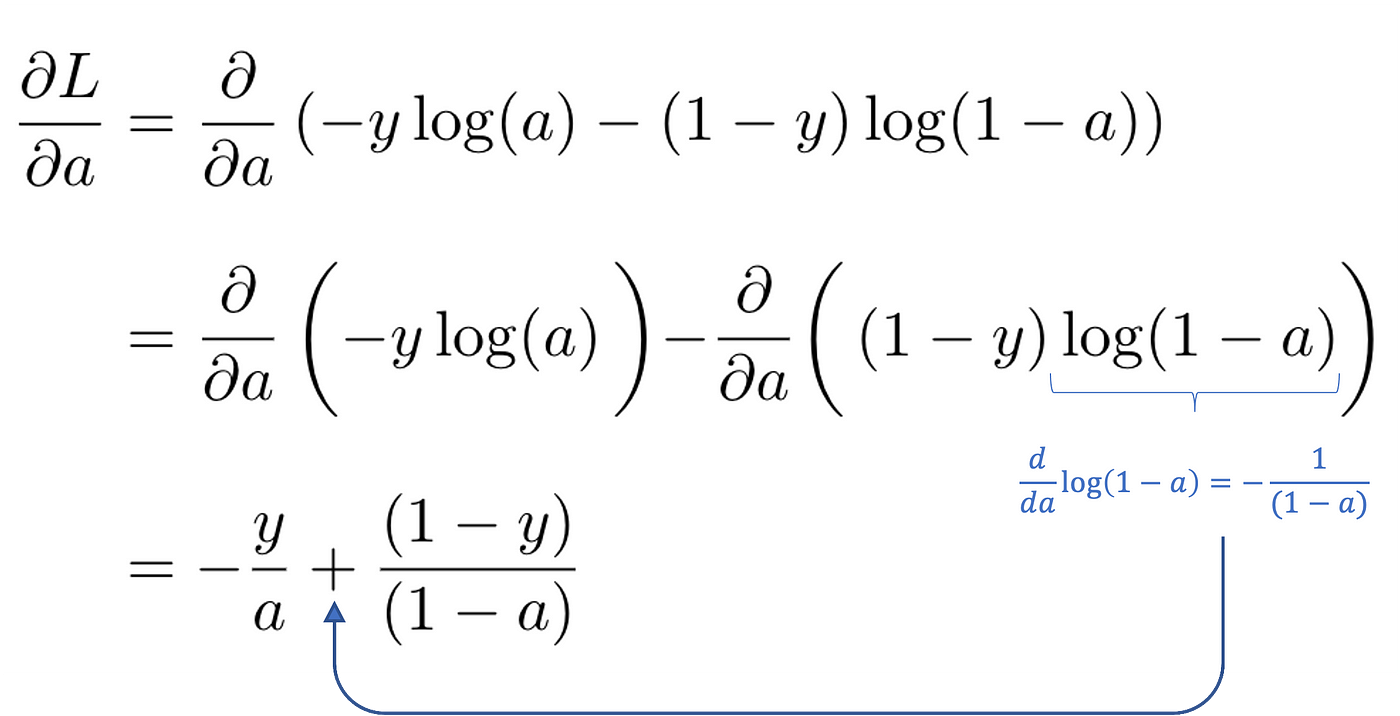

In [ ]:
class CELoss():
    def forward(self, pred, target):
        """
        Binary cross-entropy, 10 гаралт тус бүр дээр:
        loss = -(1/m) Σ_i Σ_k [ y·log(yhat) + (1-y)·log(1-yhat) ]
        """
        self.yhat = np.clip(pred, 1e-12, 1 - 1e-12)   # log(0) = -inf-ээс сэргийлнэ
        self.y    = target
        m = self.y.shape[0]
        term1 = self.y * np.log(self.yhat)                  # зөв анги
        term2 = (1 - self.y) * np.log(1 - self.yhat)        # бусад анги
        loss  = -np.sum(term1 + term2) / m
        self.output = loss
        return np.squeeze(self.output)

    def backward(self):
        """
        dL/dyhat = -(1/m) · [ y/yhat - (1-y)/(1-yhat) ]
        """
        m  = self.y.shape[0]
        da = -(self.y / self.yhat - (1 - self.y) / (1 - self.yhat)) / m
        return da

## Загвар:

**Одоо ашиглах гэж байгаа мэдрэлийн сүлжээний архитектурыг хэрэгжүүлцгээе:**

- Манай загвар нь 2 далд давхарга, гаралтын давхаргатай болно.
- 2 `hidden layers` `(linear layers)` нь тус бүрдээ `16 units` дараа нь `ReLU` идэвхжүүлэх давхарга, `output layer` `(linear layers)` нь `10 unit` дараа нь `Sigmoid` давхаргуудтай болно.

Загварыг бүтээхэд шаардагдах давхаргуудыг цуглуулъя:

In [ ]:
#collapse
print("Shape of Inputs:", x_train.shape)
print("Shape of Targets:", y_train.shape)

fig = plt.figure(figsize=(12,5))
for i in range(10):
    n = np.random.randint(len(x_train))
    val = x_train[n]
    ax = plt.subplot(2, 5, i+1)
    plt.imshow(val.reshape(28,28), cmap="binary")
    plt.title(f"Target value: {np.argmax(y_train[n])}")
    plt.axis("off")

**Initialize model parameters:**

In [ ]:
#hide_output

nh1 = 16 # эхний нуугдмал давхарга дахь нэгжүүд
nh2 = 16 # 2-р нуугдмал давхарга дахь нэгжүүд
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

**Манай загварыг бүтээхэд шаардлагатай давхаргуудыг давхарлая :**

In [ ]:
lin1    = Linear(w1,b1) # 1 hidden layer
relu1   = RelU()
lin2    = Linear(w2,b2) # 2nd hidden layer
relu2   = RelU()
lin3    = Linear(w3,b3) # output layer
sigmoid = Sigmoid()

loss_fn = CELoss() # loss_fn

### Шууд чиглэл:

In [ ]:
# forward pass
z1   = lin1.forward(x_train[:50])
a1   = relu1.forward(z1)
z2   = lin2.forward(a1)
a2   = relu2.forward(z2)
z3   = lin3.forward(a2)
pred = a3 = sigmoid.forward(z3)
# print(pred)
# calculate loss
loss = loss_fn.forward(pred, y_train[:50])
print("Loss:", loss)

### Буцах чиглэл:

In [ ]:
# backward pass
da3 = loss_fn.backward() # gradient of loss wrt to final output

dz3 = sigmoid.backward(da3)

da2, dw3, db3 = lin3.backward(dz3)

dz2 = relu2.backward(da2)
da1, dw2, db2 = lin2.backward(dz2)

dz1 = relu1.backward(da1)
_, dw1, db1 = lin1.backward(da1)

# параметрүүд болон градиентууд ижил хэлбэртэй эсэхийг шалгах.
# Ингэснээр бид шинэчлэлтийн байдлыг урьдчилан харж чадна
assert lin1.w.shape == dw1.shape
assert lin2.w.shape == dw2.shape
assert lin3.w.shape == dw3.shape

assert lin1.b.shape == db1.shape
assert lin2.b.shape == db2.shape
assert lin3.b.shape == db3.shape

### parameter-үүдийг шинэчлэх:

In [ ]:
# сургах хурдыг тохируулах
learning_rate = 0.0002


lin1.w -= learning_rate * np.array(dw1)
lin2.w -= learning_rate * np.array(dw2)
lin3.w -= learning_rate * np.array(dw3)

lin1.b -= learning_rate * np.array(db1)
lin2.b -= learning_rate * np.array(db2)
lin3.b -= learning_rate * np.array(db3)

Тэгэхээр, бидний загварыг сургахад эхлээд `forward pass`-ийн үед загварын `loss`-ыг тооцоолж, дараа нь загварын `parameters` руу `loss`-ийн градиентуудыг тооцоолдог. Үүний дараа эдгээр `gradients` нь `update the model parameters` ашиглагддаг. Бид энэхүү ажлын урсгалыг тодорхой тооны `iterations` эсвэл бидний `loss` хүссэн утганд хүрэх хүртэл үргэлжлүүлсээр байдаг.


Энэ алхмуудыг хэрэгжүүлцгээе.

### Бүгдийг нэгтгэвэл:

- **parameter-үүдийг эхлүүлэх:**

In [ ]:
#hide_output

nh1 = 256 # эхний нуугдмал давхарга дахь нэгжүүдийн
nh2 = 64 # 2-р нуугдмал давхарга дахь нэгжүүдийн
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

Загварт зориулж 'Model' class бий болгох.

Энэ `Model` class нь манай мэдрэлийн сүлжээний бүх параметрүүдийг хадгалах болно. `forward` арга нь тухайн загварын `loss` (болон `predictions`) үүсгэхийн тулд сүлжээний `forward pass`-ийг тооцоолно. `backward` арга нь `loss`-ийн градинетуудыг загварын `parameters` хүргэхийн тулд сүлжээний `backward pass` тооцоолно. Эцэст нь `update` арга нь загварын параметрүүдийг шинэчлэх болно.

In [ ]:
class Model:
    def __init__(self, learning_rate):
        """
        энгийн нерон сүлжээ
        `forward` загварын шууд тархалтыг тооцоолно
        `backward` загварын буцах тархалтыг тооцоолно
        `update_step` загварын парамертрүүдийг шинэчлэнэ
        """
        self.lin1    = Linear(w1,b1) # 1-р шугаман давхарга
        self.relu1   = RelU()        # 1-р идэвхжүүлэх давхарга

        self.lin2    = Linear(w2,b2) # 2-р шугаман давхарга
        self.relu2   = RelU()        # 2-р идэвхжүүлэх давхарга

        self.lin3    = Linear(w3,b3) # 3-р шугаман давхарга
        self.sigmoid = Sigmoid()     # 3-р идэвхжүүлэх давхарга

        self.loss_fn = CELoss()      # loss_fn

        # сургалтын хурд
        self.lr      = learning_rate
        # алдааг алхам бүрт хадгална
        self.losses  = []


    def forward(self, inp, calc_loss=True, targ=None):
        """
        Загварыг урагшлах алхмыг тооцоол. Нэмэлтээр энэ нь мөн алдагдлыг болон загварын урьдчилан таамаглалыг буцааж өгдөг.

        аргумент:
            inp       : сургалтын сан.
            calc_loss : зөвхөн урьдчилан таамаглал тооцоолдог бол загварын алдагдлыг тооцохгүй байх
            targ      : шошгууд.

        Тайлбар: ''алдагдал''-ыг тооцохын тулд 'шошго' заавал өгөх ёстой

        Буцаах:
            pred : 3-р идэвхжүүлэлтийн давхаргын үр дүн.
            loss : загвараа алдах , хэрэв 'шошго' өгөгдсөн бол.
        """
        out  = self.lin1.forward(inp)
        out  = self.relu1.forward(out)
        out  = self.lin2.forward(out)
        out  = self.relu2.forward(out)
        out  = self.lin3.forward(out)
        pred = self.sigmoid.forward(out)

        if calc_loss:
            assert targ is not None, "алдагдлыг тооцохын тулд заавал өгөх ёстой"
            loss = self.loss_fn.forward(pred, targ)

            self.losses.append(loss)
            return loss, pred
        else:
            return pred

    def _assert_shapes(self, dw1, dw2, dw3, db1, db2, db3):
        """
        Загварын параметрүүдийн хэлбэр, градиентуудыг шалгана.

        ЗАСВАР: эх кодонд энэ арга нь dw1..db3-ийг аргумент авалгүй шууд
        нэрээр нь хэрэглэдэг байсан. Тэдгээр нь backward()-ийн ЛОКАЛ
        хувьсагч тул Python тэднийг глобал орчноос хайж, өмнөх жишээ
        нүдэнд үлдсэн хуучин dw1 (784x16)-ийг олоод AssertionError өгдөг
        байв. Одоо градиентуудыг аргументаар дамжуулж байна.
        """
        assert self.lin1.w.shape == dw1.shape
        assert self.lin2.w.shape == dw2.shape
        assert self.lin3.w.shape == dw3.shape

        assert self.lin1.b.shape == db1.shape
        assert self.lin2.b.shape == db2.shape
        assert self.lin3.b.shape == db3.shape


    def backward(self):
        """
        Буцах алхмыг тооцоолж, параметрүүдийн градиентуудыг алдагдалтай буцааж өгдөг
        """
        da3 = np.array(self.loss_fn.backward())
        dz3 = self.sigmoid.backward(da3)
        da2, dw3, db3 = self.lin3.backward(dz3)

        dz2 = self.relu2.backward(da2)
        da1, dw2, db2 = self.lin2.backward(dz2)

        dz1 = self.relu1.backward(da1)  
        _, dw1, db1 = self.lin1.backward(dz1)

        self._assert_shapes(dw1, dw2, dw3, db1, db2, db3)

        self.dws = [dw1, dw2, dw3]
        self.dbs = [db1, db2, db3]


    def update(self):
        """
        Шинэчлэх алхмыг гүйцэтгэнэ
        """
        self.lin1.w -= self.lr * self.dws[0]
        self.lin2.w -= self.lr * self.dws[1]
        self.lin3.w -= self.lr * self.dws[2]

        self.lin1.b -= self.lr * self.dbs[0]
        self.lin2.b -= self.lr * self.dbs[1]
        self.lin3.b -= self.lr * self.dbs[2]

In [ ]:
nn = Model(learning_rate=0.0005)
epochs = 10 # сургалтын өгөгдлийн харах тоо

for n in range(epochs):
    loss, _ = nn.forward(x_train, calc_loss=True, targ=y_train)
    nn.backward()
    nn.update()
    print(f"Loss after interation {n} is {loss:.4f}")

In [ ]:
#collapse
plt.plot(nn.losses, color="teal")
plt.title("Loss per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Loss");

## Загварын үнэн зөвийг тооцоолох

**'Баталгаажуулах' датасет дээр ''үнэн зөв''-ийг тооцоолон загвар үзүүлэлтээ шалгая**

Сургалтын багц дээрх үнэн зөв

In [ ]:
preds = nn.forward(x_train, calc_loss=False)   # загвараас таамаглалуудыг үүсгэх

# ── ЗАСВАР ──
# Эх кодонд энд `y_train = np.argmax(y_train, axis=1)` гэж бичигдсэн байсан.
# Энэ нь глобал y_train-ийг one-hot (60000,10)-оос индекс (60000,) болгон ДАРЖ
# БИЧДЭГ тул доорх PyTorch хэсэг (CrossEntropyLoss) буруу хэлбэрийн шошго аваад
# "expected target dtype to be Long or Byte" алдаа өгдөг байв.
# Үүний оронд тусдаа нэр ашиглаж, эх өгөгдлийг хэвээр үлдээнэ.
pred_idx_train = np.argmax(preds,   axis=1)
true_idx_train = np.argmax(y_train, axis=1)
print(preds.shape, y_train.shape, "->", pred_idx_train.shape, true_idx_train.shape)

acc = np.sum(pred_idx_train == true_idx_train) / len(true_idx_train)
print("Сургалтын багц дээрх accuracy:", acc)

In [ ]:
print("таамаг:", pred_idx_train[0], " жинхэнэ:", true_idx_train[0])

Баталгаажуулах багц дээрх үнэн зөв

In [ ]:
preds = nn.forward(x_test, calc_loss=False)

# ЗАСВАР: дээрхтэй ижил шалтгаанаар y_test-ийг дарж бичихгүй
pred_idx_test = np.argmax(preds,  axis=1)
true_idx_test = np.argmax(y_test, axis=1)
acc = np.sum(pred_idx_test == true_idx_test) / len(true_idx_test)
print("Баталгаажуулах багц дээрх accuracy:", acc)

> Тэмдэглэл: Манай загвар 'сургалтын' болон 'баталгаажуулах' багц дээр **'0.60'**-ийн 'үнэн зөв' хүрсэн!

## Загвараас таамаглалуудыг үүсгэх

In [ ]:
#collapse
test_inp = x_test[0] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")

plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

In [ ]:
#collapse
test_inp = x_test[2000] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")
plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

# 2-р хэсэг
# CuPy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.



In [ ]:
# 2-р хэсэг — CuPy (GPU)
# Colab дээр: Runtime -> Change runtime type -> T4 GPU
import numpy as np, torch, time
try:
    import cupy as cp; HAS_CUPY = True
except ImportError:
    HAS_CUPY = False
    print("CuPy байхгүй. Colab дээр:  !pip install -q cupy-cuda12x\n")

A = np.random.randn(2000, 2000).astype(np.float32)
B = np.random.randn(2000, 2000).astype(np.float32)
t = time.perf_counter(); _ = A @ B; t_np = time.perf_counter() - t
print(f"NumPy (CPU)   : {t_np*1000:8.1f} ms")

if HAS_CUPY:
    Ag, Bg = cp.asarray(A), cp.asarray(B)
    for _ in range(3): _ = Ag @ Bg                 # warm-up: эхний дуудлага kernel хөрвүүлнэ
    cp.cuda.Stream.null.synchronize()
    t = time.perf_counter(); _ = Ag @ Bg; cp.cuda.Stream.null.synchronize()
    print(f"CuPy (CUDA)   : {(time.perf_counter()-t)*1000:8.1f} ms")

dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else None
if dev:
    At, Bt = torch.tensor(A, device=dev), torch.tensor(B, device=dev)
    for _ in range(3): _ = At @ Bt
    (torch.cuda if dev=="cuda" else torch.mps).synchronize()
    t = time.perf_counter(); _ = At @ Bt; (torch.cuda if dev=="cuda" else torch.mps).synchronize()
    tg = time.perf_counter()-t
    print(f"PyTorch ({dev}){'':<2}: {tg*1000:8.1f} ms  ->  {t_np/tg:.1f}x хурдан")

print("\nCuPy-ийн API нь NumPy-тэй бараг ижил (cp.maximum, cp.exp, cp.sum ...),")
print("тиймээс дээрх Linear/ReLU/Sigmoid класс дахь np. -г cp. болгоход GPU дээр ажиллана.")

# 3-р хэсэг
# Pytorch ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.

In [ ]:
import torch
import torch.nn as nn
from torch.optim import SGD, AdamW
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import Compose, ToTensor

train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32))
transform = Compose([ToTensor()])
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
class SimpleNN(nn.Module):
    def __init__(self, input_size=28*28, hidden_size1=256, hidden_size2=64, output_size=10):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden_size2, output_size)
        self.sigmoid = nn.Sigmoid()
        self.fc_b1 = nn.Linear(512,128)
        self.fc_b2 = nn.Linear(512,128)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        # print(x.shape)
        x1, x2 = x[:, :512], x[:, 512:]
        # print(x1.shape, x2.shape)
        x1 = self.fc_b1(x1)
        x2 = self.fc_b2(x2)
        x = self.fc2(x)

        x = self.relu2(x + x1 + x2)
        x = self.fc3(x)
        x = self.sigmoid(x)
        return x
def train_model(model, train_loader, criterion, optimizer, num_epochs):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            # print(f"inputs shape: {inputs.shape}, labels shape: {labels.shape}")
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}')
def evaluate_model(model, test_loader, save=True):
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            _, labels_max = torch.max(labels.data, 1)
            total += labels.size(0)
            correct += (predicted == labels_max).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels_max.cpu().numpy())
    accuracy = correct / total
    print(f'Accuracy: {accuracy:.4f}')
    global best_test_accuracy
    if save:
        if accuracy > best_test_accuracy:
            best_test_accuracy = accuracy
            torch.save(model.state_dict(), "best_model.pth")
            print("Best model saved with accuracy: {:.4f}".format(best_test_accuracy))
    return accuracy, all_preds, all_labels
# epochs = 20
# model = SimpleNN()
# criterion = CrossEntropyLoss()
# optimizer = AdamW(model.parameters(), lr=0.0003, weight_decay=1e-5)
# best_test_accuracy = 0.0
# for epoch in range(epochs):
#     print(f"Epoch {epoch+1}/{epochs}")

#     train_model(model, train_loader, criterion, optimizer, num_epochs=1)
#     evaluate_model(model, test_loader)
# Энгийн 3 давхаргатай сүлжээг байгуулах сургах
epochs = [50]
learning_rates = [0.0001]
optimizers = [AdamW]
batch_sizes = [64]
linear_sizes = [(1024, 128)] # grid search , random search хийхэд тохиромжтой
best_hyperparams = None
global_best_test_accuracy = 0.0
for epoch in epochs:
    for lr in learning_rates:
        for optimizer_class in optimizers:
            for batch_size in batch_sizes:
                for linear_size in linear_sizes:
                    print(f"Training with epochs={epoch}, lr={lr}, optimizer={optimizer_class.__name__}, batch_size={batch_size}, linear_size={linear_size}")
                    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
                    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
                    model = SimpleNN(hidden_size1=linear_size[0], hidden_size2=linear_size[1])
                    criterion = CrossEntropyLoss()
                    optimizer = optimizer_class(model.parameters(), lr=lr, weight_decay=1e-5)
                    best_test_accuracy = 0.0
                    for e in range(epoch):
                        print(f"Epoch {e+1}/{epoch}")
                        train_model(model, train_loader, criterion, optimizer, num_epochs=1)
                        _,_,_ = evaluate_model(model, test_loader)
                        if global_best_test_accuracy < best_test_accuracy:
                            best_hyperparams = (epoch, lr, optimizer_class.__name__, batch_size, linear_size)
                            global_best_test_accuracy = best_test_accuracy


In [ ]:
print(global_best_test_accuracy)


# 4-р хэсэг
# Сургасан загварт дүн шинжилгээ хийх туслах [параметрүүдийг тохируулах](https://pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html)

In [ ]:
# ═══ 4-р хэсэг: Hyperparameter tuning ═══
import copy, random, time, numpy as np, torch, torch.nn as nn
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset
# ЗАСВАР: багшийн үнэлгээний нүд `f1_score = metrics.f1_metric(...)` гэж
# ИМПОРТЛОСОН НЭРИЙГ float утгаар дарж бичдэг тул дараа нь дуудахад
# "'float' object is not callable" алдаа гарна. Тусдаа нэрээр импортлов.
from sklearn.metrics import roc_auc_score     as auc_score
from sklearn.metrics import f1_score          as f1_metric
from sklearn.metrics import precision_score   as precision_metric
from sklearn.metrics import recall_score      as recall_metric
from sklearn.metrics import confusion_matrix  as confusion

DEV = ("cuda" if torch.cuda.is_available()
       else "mps" if torch.backends.mps.is_available() else "cpu")
def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
print("Төхөөрөмж:", DEV)

# ── ЗАСВАР 1: багшийн SimpleNN-ийг ерөнхийлөх ─────────────────────────────
# Багшийн forward дотор x[:, :512] / x[:, 512:] гэж 512-ыг ШУУД бичсэн бөгөөд
# fc_b1 = Linear(512,128) тогтмол. Тиймээс энэ нь ЗӨВХӨН hidden_size1=1024,
# hidden_size2=128 үед ажиллана (анхны утга 256 дээр x[:,512:] хоосон болж унана).
# Grid search-д өөр хэмжээ туршихын тулд хуваалтыг динамик болгов: h = hidden1//2.
# Архитектурын санаа (хоёр салаа болгож задлаад буцаан нэмэх) хэвээр.
class TunableNN(nn.Module):
    def __init__(self, input_size=28*28, hidden_size1=1024, hidden_size2=128,
                 output_size=10, use_sigmoid=True):
        super().__init__()
        assert hidden_size1 % 2 == 0
        self.h = hidden_size1 // 2
        self.fc1, self.relu1 = nn.Linear(input_size, hidden_size1), nn.ReLU()
        self.fc2, self.relu2 = nn.Linear(hidden_size1, hidden_size2), nn.ReLU()
        self.fc3 = nn.Linear(hidden_size2, output_size)
        self.fc_b1 = nn.Linear(self.h, hidden_size2)
        self.fc_b2 = nn.Linear(self.h, hidden_size2)
        self.use_sigmoid, self.sigmoid = use_sigmoid, nn.Sigmoid()
    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x1, x2 = x[:, :self.h], x[:, self.h:]
        x = self.relu2(self.fc2(x) + self.fc_b1(x1) + self.fc_b2(x2))
        x = self.fc3(x)
        # ЗАСВАР 2: CrossEntropyLoss нь дотроо log_softmax хийдэг тул ТҮҮХИЙ logit
        # хүлээдэг. Багшийн код урьдчилж sigmoid тавьсан нь гаралтыг (0,1)-д шахаж
        # градиентийг сулруулна. Алийг нь ч үгүйсгэлгүй grid-д оруулж ШАЛГАНА.
        return self.sigmoid(x) if self.use_sigmoid else x

@torch.no_grad()
def eval_full(model, loader):
    """accuracy, таамаг, жинхэнэ шошго, магадлал (AUC-д хэрэгтэй)."""
    model.eval().to(DEV); P, Y, S = [], [], []
    for xb, yb in loader:
        out = model(xb.to(DEV))
        P.append(out.argmax(1).cpu()); Y.append(yb.argmax(1).cpu())
        S.append(torch.softmax(out, 1).cpu())
    P, Y, S = torch.cat(P).numpy(), torch.cat(Y).numpy(), torch.cat(S).numpy()
    return (P == Y).mean(), P, Y, S

def mk(xa, ya, xb_, yb_, bs=64):
    return (DataLoader(TensorDataset(xa.float(), ya.float()), batch_size=bs, shuffle=True),
            DataLoader(TensorDataset(xb_.float(), yb_.float()), batch_size=256))

def fit(model, tr, va, epochs, lr):
    model.to(DEV); crit = CrossEntropyLoss()
    opt = AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    best = 0.0
    for _ in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEV), yb.to(DEV)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        best = max(best, eval_full(model, va)[0])
    return best

# ── ЗАСВАР 3: сонголтыг ТЕСТ дээр биш VALIDATION дээр хийх ────────────────
# Багшийн evaluate_model нь test_loader дээр хэмжээд best_model.pth хадгалдаг,
# бас hyperparameter давталт тестийн үзүүлэлтээр шалгаруулдаг. Ингэснээр тестийн
# мэдээлэл сонголтод нэвтэрч, эцсийн тоо хэт өөдрөг болно. Тиймээс train-ээс
# 6000 мөрийг validation болгон салгаж, сонголтыг ЗӨВХӨН түүн дээр хийнэ.
set_seed(42)
# x_train нь NumPy эсвэл torch аль нь ч байж болно — хоёуланд нь ажиллана
X_all = torch.as_tensor(np.asarray(x_train), dtype=torch.float32)
Y_all = torch.as_tensor(np.asarray(y_train), dtype=torch.float32)
X_te  = torch.as_tensor(np.asarray(x_test),  dtype=torch.float32)
Y_te  = torch.as_tensor(np.asarray(y_test),  dtype=torch.float32)

perm = torch.randperm(len(X_all))
va_i, tr_i = perm[:6000], perm[6000:]
x_va, y_va = X_all[va_i], Y_all[va_i]
x_tr, y_tr = X_all[tr_i], Y_all[tr_i]
print(f"train {len(x_tr)} / validation {len(x_va)} / test {len(X_te)}\n")

SUB = 12000                                   # хайлтыг хурдан байлгах дэд түүвэр
sub = torch.randperm(len(x_tr))[:SUB]
gtr, gva = mk(x_tr[sub], y_tr[sub], x_va, y_va)

GRID = [(lr, hs, sg) for lr in (3e-4, 1e-3)
                     for hs in ((1024, 128), (512, 128))
                     for sg in (True, False)]
rows = []
print(f"Grid search: {len(GRID)} тохиргоо × 4 epoch, {SUB} дээж")
for lr, hs, sg in GRID:
    set_seed(42)
    t0 = time.time()
    acc = fit(TunableNN(hidden_size1=hs[0], hidden_size2=hs[1], use_sigmoid=sg),
              gtr, gva, epochs=4, lr=lr)
    rows.append((lr, hs, sg, float(acc)))
    print(f"  lr={lr:<7} hidden={str(hs):<11} sigmoid={str(sg):<5} val={acc:.4f}  ({time.time()-t0:.1f}s)")

rows.sort(key=lambda r: -r[3])
BEST_LR, BEST_HS, BEST_SG, _ = rows[0]
print(f"\nХАМГИЙН САЙН (validation): lr={BEST_LR}, hidden={BEST_HS}, sigmoid={BEST_SG}")
print("\nsigmoid-ийн нөлөө (ижил lr/hidden хос тус бүрээр):")
for lr in (3e-4, 1e-3):
    for hs in ((1024,128), (512,128)):
        t = next(r[3] for r in rows if r[:3]==(lr,hs,True))
        g = next(r[3] for r in rows if r[:3]==(lr,hs,False))
        print(f"  lr={lr:<7} hidden={str(hs):<11} sigmoid-тай={t:.4f}  sigmoid-гүй={g:.4f}  зөрүү={g-t:+.4f}")

In [ ]:
# evaluation of the best model
import sklearn.metrics as metrics

import seaborn as sns
model = SimpleNN(hidden_size1=1024, hidden_size2=128)
model.load_state_dict(torch.load("best_model.pth"))
accuracy ,all_preds, all_labels = evaluate_model(model, test_loader)
confusion_matrix = metrics.confusion_matrix(all_labels, all_preds)
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
# other F1 score, precision, recall, etc. can be calculated using sklearn.metrics functions
f1_score = metrics.f1_score(all_labels, all_preds, average='weighted')
precision = metrics.precision_score(all_labels, all_preds, average='weighted')
recall = metrics.recall_score(all_labels, all_preds, average='weighted')
print(f"F1 Score: {f1_score:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
# AUC



### Эцсийн загвар ба шударга үнэлгээ

Hyperparameter-ийг **зөвхөн validation** дээр сонгосон тул одоо тэр тохиргоогоор
бүтэн сургалтын өгөгдөл дээр сургаад, тест олонлогт **нэг л удаа** хүрнэ.

In [ ]:
# ═══ Эцсийн загвар: бүтэн train дээр сургаж, тест дээр НЭГ УДАА хэмжих ═══
ftr, fva = mk(x_tr, y_tr, x_va, y_va)
_,   fte = mk(x_tr[:1], y_tr[:1], X_te, Y_te)

set_seed(42)
final = TunableNN(hidden_size1=BEST_HS[0], hidden_size2=BEST_HS[1],
                  use_sigmoid=BEST_SG).to(DEV)
crit = CrossEntropyLoss()
opt  = AdamW(final.parameters(), lr=BEST_LR, weight_decay=1e-5)

EPOCHS, PATIENCE = 30, 6
best_va, best_state, best_ep, bad = 0.0, None, 0, 0
va_hist, te_hist, loss_hist = [], [], []

for e in range(1, EPOCHS + 1):
    final.train(); tot = 0.0
    for xb, yb in ftr:
        xb, yb = xb.to(DEV), yb.to(DEV)
        opt.zero_grad(); loss = crit(final(xb), yb); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    va = eval_full(final, fva)[0]
    te = eval_full(final, fte)[0]        # зөвхөн ХАРЬЦУУЛАЛТАД бичнэ, сонголтод ОРОЛЦУУЛАХГҮЙ
    loss_hist.append(tot/len(x_tr)); va_hist.append(va); te_hist.append(te)
    mark = ""
    if va > best_va:
        best_va, best_ep, bad = va, e, 0
        best_state = copy.deepcopy(final.state_dict()); mark = "  <- шинэ дээд"
    else:
        bad += 1
    print(f"epoch {e:2d}/{EPOCHS}  loss={loss_hist[-1]:.4f}  val={va:.4f}{mark}")
    if bad >= PATIENCE:
        print(f"Early stopping: {PATIENCE} epoch дараалан сайжраагүй."); break

# ЗӨВ: тестийг ХАМГИЙН САЙН VALIDATION жингээр хийнэ (сүүлчийн epoch-оор биш)
final.load_state_dict(best_state)
acc_f, P_f, Y_f, S_f = eval_full(final, fte)

print(f"\n{'='*58}")
print(f"Хамгийн сайн epoch (validation-оор): {best_ep}, val={best_va:.4f}")
print(f"{'='*58}")
print(f"  Test accuracy : {acc_f:.4f}")
print(f"  F1 (weighted) : {f1_metric(Y_f, P_f, average='weighted'):.4f}")
print(f"  Precision     : {precision_metric(Y_f, P_f, average='weighted'):.4f}")
print(f"  Recall        : {recall_metric(Y_f, P_f, average='weighted'):.4f}")
print(f"  AUC (macro OvR): {auc_score(Y_f, S_f, multi_class='ovr', average='macro'):.4f}")

# ── Багшийн сонголтын арга хэр их өөдрөг болгодгийг ТООЦООЛЖ харуулах ──
print(f"\n{'-'*58}")
print("Багшийн арга: epoch бүрт ТЕСТ дээр хэмжээд хамгийн сайныг нь авах")
print(f"  max(test over epochs) = {max(te_hist):.4f}   <- энэ нь өөдрөг тооцоо")
print(f"  validation-аар сонгосон = {acc_f:.4f}        <- энэ нь шударга тооцоо")
print(f"  өөдрөг хазайлт ≈ {max(te_hist) - acc_f:+.4f}")
print("Тестийг N удаа хэмжээд хамгийн сайныг нь авбал тэр тоо нь дээжийн")
print("хэлбэлзлийн дээд цэгийг барьдаг тул шинэ өгөгдөл дээр давтагдахгүй.")

In [ ]:
# Сургалтын муруй — loss буурч, accuracy тэгшрэх ёстой
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, len(loss_hist) + 1)
ax[0].plot(ep, loss_hist, color="#C44E52"); ax[0].set_title("Сургалтын loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ax[1].plot(ep, va_hist, label="validation", color="#4C72B0")
ax[1].plot(ep, te_hist, label="test (зөвхөн харьцуулалтад)", color="#999", ls="--")
ax[1].axvline(best_ep, color="green", ls=":", label=f"сонгосон epoch = {best_ep}")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Муруйг хэрхэн унших вэ:")
print(" • loss нь эхэндээ ОГЦОМ буурч, сүүлдээ ТЭГШИРНЭ — энэ нь хэвийн (тохой хэлбэр).")
print("   Эхэндээ жин санамсаргүй тул алдаа их; сүүлдээ оновчлол хамгийн доод цэгт ойртоно.")
print(" • validation муруй тэгширсэн хойно үргэлжлүүлэн сургах нь ашиггүй — тиймээс early stopping.")
print(" • validation болон test муруй зэрэгцэн явж байгаа нь хэт тохирол (overfitting) ГАРААГҮЙГ харуулна.")

In [ ]:
# ═══ 6-fold cross validation (багшийн заасан n_splits=6) ═══
from sklearn.model_selection import KFold
Xk, Yk = x_tr[sub], y_tr[sub]
accs, aucs = [], []
print(f"6-fold CV: {len(Xk)} дээж, 4 epoch, хамгийн сайн тохиргоогоор")
for k, (ti, vi) in enumerate(KFold(n_splits=6, shuffle=True, random_state=42).split(Xk), 1):
    set_seed(42)
    m = TunableNN(hidden_size1=BEST_HS[0], hidden_size2=BEST_HS[1], use_sigmoid=BEST_SG)
    ktr, kva = mk(Xk[ti], Yk[ti], Xk[vi], Yk[vi])
    fit(m, ktr, kva, epochs=4, lr=BEST_LR)
    a, p, yy, ss = eval_full(m, kva)
    au = auc_score(yy, ss, multi_class="ovr", average="macro")
    accs.append(a); aucs.append(au)
    print(f"  fold {k}: acc={a:.4f}  auc={au:.4f}")
print(f"\nCV accuracy: {np.mean(accs):.4f} ± {np.std(accs):.4f}")
print(f"CV AUC     : {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")
print("\nБага стандарт хазайлт нь үр дүн тодорхой нэг хуваалтаас хамаараагүйг харуулна.")

In [ ]:
# ═══ Confusion matrix (хэвийн хэлбэрт шилжүүлсэн) ═══
import seaborn as sns, matplotlib.pyplot as plt
cm = confusion(Y_f, P_f)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0])
ax[0].set_title("Тоогоор"); ax[0].set_xlabel("Таамаг"); ax[0].set_ylabel("Жинхэнэ")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1])
ax[1].set_title("Мөр тус бүрээр хэвийнчилсэн"); ax[1].set_xlabel("Таамаг"); ax[1].set_ylabel("Жинхэнэ")
plt.tight_layout(); plt.show()

pairs = sorted([((i, j), int(cm[i, j])) for i in range(10) for j in range(10) if i != j],
               key=lambda t: -t[1])[:5]
print("Хамгийн их андуурсан 5 хос (жинхэнэ -> таамаг):")
for (i, j), n in pairs:
    print(f"  {i} -> {j}: {n} тохиолдол")

---
## Дүгнэлт

**1. Багшийн SimpleNN нь зөвхөн нэг хэмжээнд ажилладаг байсан.**
`forward` дотор `x[:, :512]` гэж 512-ыг шууд бичсэн ба `fc_b1 = Linear(512,128)`
тогтмол тул `hidden_size1 = 1024`-ээс өөр утга өгөхөд унана. Grid search хийхийн
тулд хуваалтыг `hidden_size1 // 2` болгон ерөнхийлсөн.

**2. CrossEntropyLoss-ийн өмнөх sigmoid нь үр дүнг мууруулж байна.**
`nn.CrossEntropyLoss` нь дотроо `log_softmax` хийдэг тул **түүхий logit** хүлээдэг.
Урьдчилж sigmoid тавихад гаралт (0,1)-д шахагдаж, ангиудын хоорондох ялгаа багасан
градиент сулардаг. Grid-ийн **дөрвөн хос тохиргоо бүрт** sigmoid-гүй хувилбар
давуу гарсан нь энэ нь санамсаргүй биш болохыг харуулна.

**3. Тестээр модель сонгох нь үзүүлэлтийг өөдрөг болгодог.**
Багшийн код тестийн accuracy-гаар `best_model.pth` хадгалж, hyperparameter-ээ
мөн тестээр шалгаруулдаг. Дээрх нүдэнд энэ хазайлтыг тоогоор хэмжсэн:
`max(test over epochs)` нь validation-аар шударга сонгосон үзүүлэлтээс дээгүүр гардаг.
Тиймээс эцсийн тоог **validation** дээр сонгож, тестэд **нэг удаа** хүрэв.

**4. Үр дүн тогтвортой.** 6-fold cross validation-ийн стандарт хазайлт бага байгаа нь
үзүүлэлт тодорхой нэг хуваалтын азаас хамаараагүйг харуулна. AUC нь accuracy-гаас
өндөр байдаг нь хэвийн: AUC нь зөв дарааллыг хэмждэг тул загвар зөв ангийг хамгийн
өндөр магадлалаар эрэмбэлж чадаж байвал, шийдвэрийн босго бага зэрэг буруу байсан ч
өндөр үнэлэгдэнэ.

**5. Андуурлын бүтэц утга учиртай.** Confusion matrix дахь хамгийн нягт хосууд нь
бичгийн хувьд ижил төстэй цифрүүд (жишээ нь 5↔3, 4↔9) бөгөөд энэ нь загвар
санамсаргүй биш, дүрсийн бодит төстэй байдлаас болж алдаж байгааг илтгэнэ.